In [2]:
%load_ext autoreload
%autoreload 2
import ImageToMatrix as itm
import matplotlib.pyplot as plt
import numpy as np
from matt_enkel import entropi, korrelation


Encrypting image with shape:  (512, 512, 3)
The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


Korrelation orig/dekrypterad:  0.0281  Entropi denkrypteradbild:   7.4965


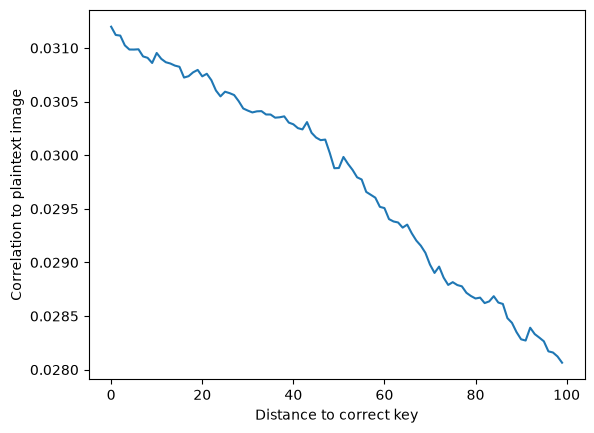

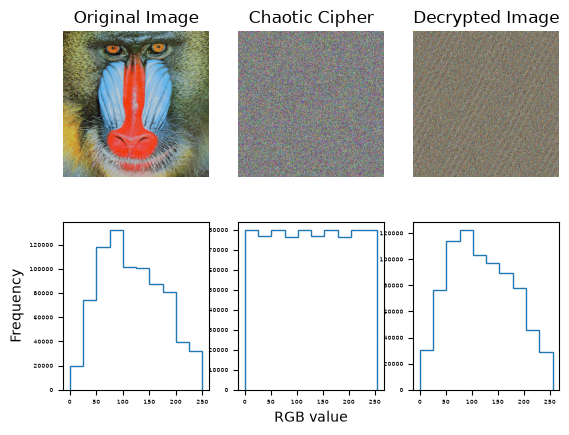

In [24]:

# Samma bilder som i ImageToMatrix.py
iterations = 100
finetune = 1  # Välj från 1-5, högre värde ger sämre granularitet men större förändring
original = itm.matrix
krypterad = itm.chaoticencryptedArray.reshape(original.shape)
ratt_nycklar = itm.chaotickeys.T
nearMissnycklar = np.empty(
    (iterations + 1, *ratt_nycklar.shape), dtype=ratt_nycklar.dtype
)
tmpnyckel = ratt_nycklar.copy()

for i in range(iterations):
    nearMissnycklar[i] = tmpnyckel.copy()
    start = i * 512 * finetune
    end = start + 512 * finetune  # change one row of pixels at a time
    tmpnyckel[start:end, :] = (
        tmpnyckel[start:end, :] + np.random.choice([-20 * finetune, 20 * finetune])
    ) % 256  # Mindre nogrann större förändring
    # tmpnyckel[start:end,:] ^= 1 #supernogrann liten förändring

# nearMissnycklar[iterations][0:512*512,:] = (tmpnyckel[0:512*512,:]+ np.random.choice([-200*finetune , 200*finetune]))%256
# nearMissnycklar[iterations, 0:512*512,:] ^=1

# --- Dekryptering med rätt nycklar------------------------------------------------------------
# desubstituerad = np.bitwise_xor(krypterad.reshape(-1,3), ratt_nycklar)
# dekrypterad = itm.InverseArnoldCatMapTransform(desubstituerad.reshape(original.shape),10, 1, 1)
desubstituerad = np.bitwise_xor(krypterad.reshape(-1, 3), ratt_nycklar).reshape(
    original.shape
)
dekrypterad = itm.InverseArnoldCatMapTransform(desubstituerad, 10, 1, 1)
# print(
#      f"Korrelation orig/orig:  {korrelation(original, original):.4f}"
#      f"  Entropi originalbild:   {entropi(original):.4f}"
# )

# # --- Dekryptering med Near-Miss keys ------------------------------------------------------------
nyckelKedja = np.empty((iterations, *original.shape), dtype=original.dtype)
korrarr = np.arange(iterations, dtype=float)
for i in range(iterations):
    desubstituerad = np.bitwise_xor(
        krypterad.reshape(-1, 3), nearMissnycklar[i]
    ).reshape(original.shape)
    dekrypterad = itm.InverseArnoldCatMapTransform(desubstituerad, 10, 1+1, 1)
    nyckelKedja[i] = dekrypterad
    korrarr[i] = korrelation(original, dekrypterad)
    # print(
    #     f"Korrelation orig/dekrypterad:  {korrelation(original, dekrypterad):.4f}"
    #     f"  Entropi enkrypteringbild:   {entropi(krypterad):.4f}"
    # )

print(
    f"Korrelation orig/dekrypterad:  {korrelation(original, dekrypterad):.4f}"
    f"  Entropi denkrypteradbild:   {entropi(dekrypterad):.4f}"
)
np.arange(iterations)
plt.plot(np.arange(iterations), korrarr)
plt.xlabel("Distance to correct key")
plt.ylabel("Correlation to plaintext image")
plt.show()
itm.plotImages(original, krypterad, nyckelKedja[-1])


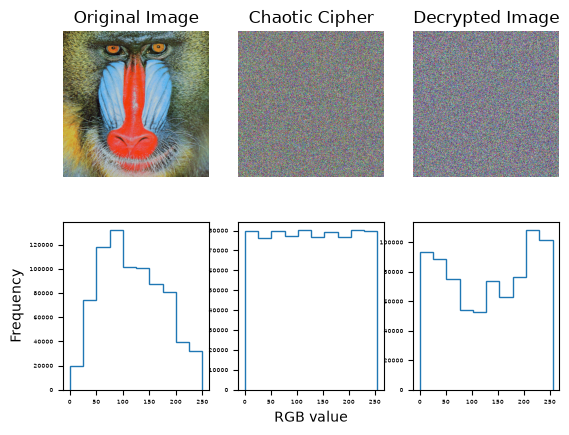

In [25]:

itm.plotImages(original, krypterad, nyckelKedja[-1])


In [13]:
#stationär i (0, 0, 0)
# print(itm.matrix - itm.ArnoldCatMapTransform(itm.matrix, 10, 1, 1))
# print(itm.matrix)
# print(itm.matrix[0][1][0])
print(ratt_nycklar.shape)
print(nearMissnycklar[0].shape)


(262144, 3)
(262144, 3)
